# Module 13 — Exercises — Solutions

Exercises for **Module 13 — Linear models and regularisation**. They follow the order of the
[concept guide](README.md): the normal equations and $R^2$, polynomial features and
standardisation, soft-thresholding, ridge in closed form, the lasso by coordinate descent,
the logistic-regression gradient and Newton step, the bias–variance decomposition by
simulation, $k$-fold cross-validation, a conceptual question on standardisation, Poisson
regression with an offset, the leave-one-out shortcut, and a mini-project on the diabetes
data. Use only NumPy (plus the scikit-learn objects named in a prompt) and keep everything
seeded.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge, Lasso, PoissonRegressor
from sklearn.preprocessing import PolynomialFeatures
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings("ignore")

def make_design(n=60, seed=0):
    # six standardised features; x1 is a noisy copy of x0, x3 overlaps x2; centred target
    g = np.random.default_rng(seed)
    Z = g.normal(size=(n, 6))
    Z[:, 1] = Z[:, 0] + 0.2 * g.normal(size=n)
    Z[:, 3] = 0.6 * Z[:, 2] + 0.8 * g.normal(size=n)
    X = (Z - Z.mean(axis=0)) / Z.std(axis=0)
    beta_true = np.array([2., 0., -1.5, 0.8, 0., 0.])
    y = X @ beta_true + 1.5 * g.normal(size=n)
    return X, y - y.mean(), beta_true

def make_poly_diabetes():
    # all 65 degree-2 features of the diabetes data, standardised; centred target
    X, y = load_diabetes(return_X_y=True)
    P = PolynomialFeatures(degree=2, include_bias=False).fit_transform(X)
    P = (P - P.mean(axis=0)) / P.std(axis=0)
    return P, y - y.mean()

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — OLS via the normal equations and R^2  `★☆☆`

Implement

* `ols_fit(X, y)` — the least-squares coefficients $\hat\beta = (X^\top X)^{-1}X^\top y$ for a
  design matrix `X` (which already contains the intercept column if one is wanted). Use
  `np.linalg.solve` on the normal equations; do **not** call `lstsq`, `pinv` or `inv`.
* `r_squared(y, y_hat)` — the coefficient of determination $R^2 = 1 - \operatorname{RSS}/\operatorname{TSS}$
  as a Python `float`, with $\operatorname{TSS} = \sum_i (y_i - \bar y)^2$.

The first checks use the five-point example of the concept guide, $x = (1,2,3,4,5)$,
$y = (2,3,5,4,6)$, whose answer you can verify by hand.

In [3]:
def ols_fit(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

def r_squared(y, y_hat):
    rss = np.sum((y - y_hat) ** 2)
    tss = np.sum((y - np.mean(y)) ** 2)
    return float(1.0 - rss / tss)

**Check your answer:**

In [4]:
_x5 = np.array([1., 2., 3., 4., 5.]); _y5 = np.array([2., 3., 5., 4., 6.])
_X5 = np.column_stack([np.ones(5), _x5])
try:
    b5 = ols_fit(_X5, _y5)
except Exception:
    b5 = None
check_close('five-point example: beta = (1.3, 0.9)', b5, np.array([1.3, 0.9]), tol=1e-9)
try:
    r2_5 = r_squared(_y5, _X5 @ b5)
except Exception:
    r2_5 = None
check_close('five-point example: R^2 = 0.81', r2_5, 0.81, tol=1e-9)
_g = np.random.default_rng(3)
_X = np.column_stack([np.ones(50), _g.normal(size=(50, 3))])
_y = _X @ np.array([1.0, 2.0, -1.0, 0.5]) + _g.normal(size=50)
try:
    b = ols_fit(_X, _y)
except Exception:
    b = None
check_close('matches np.linalg.lstsq on a 50 x 4 design', b, np.linalg.lstsq(_X, _y, rcond=None)[0], tol=1e-8)
check('residual is orthogonal to the columns (X^T e = 0)', b is not None and np.allclose(_X.T @ (_y - _X @ b), 0, atol=1e-8))
try:
    r2 = r_squared(_y, _X @ b)
except Exception:
    r2 = None
check('R^2 is a Python float between 0 and 1', isinstance(r2, float) and 0 < r2 < 1)
check_hash('hidden: R^2 of the 50-point fit (3 decimals)', r2, 'c29699d04c899bb3')

✅ five-point example: beta = (1.3, 0.9)
✅ five-point example: R^2 = 0.81
✅ matches np.linalg.lstsq on a 50 x 4 design
✅ residual is orthogonal to the columns (X^T e = 0)
✅ R^2 is a Python float between 0 and 1
✅ hidden: R^2 of the 50-point fit (3 decimals)


True

**Why this works**

The normal equations $X^\top X\hat\beta = X^\top y$ say the residual is orthogonal to every
column of $X$; `np.linalg.solve` solves them without forming an explicit inverse, which is
both faster and more accurate. $R^2$ compares the residual sum of squares with the spread of
$y$ around its mean, so it is the fraction of variance the model explains; with an intercept
in the model it lies in $[0, 1]$. For the five-point data the hand calculation gives
$\hat\beta = (1.3, 0.9)$, $\operatorname{RSS} = 1.9$, $\operatorname{TSS} = 10$. A common
wrong turn is to compute TSS around zero instead of around $\bar y$, which inflates $R^2$.

## Exercise 2 — Polynomial features and standardisation  `★☆☆`

Implement

* `poly_features(x, degree)` — for a 1-D array `x` of length $n$, the $n\times(\text{degree}+1)$
  design matrix with columns $x^0, x^1, \dots, x^{\text{degree}}$ (in that order). Do not use
  `np.vander` or `PolynomialFeatures`.
* `standardize(X)` — return `(Z, mean, std)` where `Z` has each column of `X` centred and
  divided by its (population, `ddof=0`) standard deviation.

The checks confirm that a degree-9 polynomial interpolates 10 points exactly and that
standardising shrinks the condition number of a polynomial design matrix.

In [5]:
def poly_features(x, degree):
    x = np.asarray(x, dtype=float)
    return np.column_stack([x ** k for k in range(degree + 1)])

def standardize(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    return (X - mean) / std, mean, std

**Check your answer:**

In [6]:
_x = np.array([0.5, 1.0, 2.0])
try:
    Phi = poly_features(_x, 3)
except Exception:
    Phi = None
check('poly_features(x, 3) has shape (3, 4)', Phi is not None and Phi.shape == (3, 4))
check_close('columns are 1, x, x^2, x^3', Phi, np.vander(_x, 4, increasing=True), tol=1e-12)
_x10 = np.linspace(0, 1, 10); _y10 = np.sin(2 * np.pi * _x10)
try:
    _V = poly_features(_x10, 9)
    _c = np.linalg.solve(_V, _y10)
    _interp_err = float(np.abs(_V @ _c - _y10).max())
except Exception:
    _interp_err = None
check('degree 9 interpolates 10 points exactly', _interp_err is not None and _interp_err < 1e-6)
_g = np.random.default_rng(5)
_X = _g.normal(size=(40, 3)) * np.array([1.0, 100.0, 0.01]) + np.array([5.0, -3.0, 0.2])
try:
    Z, mu, sd = standardize(_X)
except Exception:
    Z, mu, sd = None, None, None
check('standardised columns have mean 0', Z is not None and np.allclose(Z.mean(axis=0), 0, atol=1e-10))
check('standardised columns have standard deviation 1 (ddof=0)', Z is not None and np.allclose(Z.std(axis=0), 1, atol=1e-10))
check('mean and std returned correctly', mu is not None and np.allclose(mu, _X.mean(axis=0)) and np.allclose(sd, _X.std(axis=0)))
try:
    _xr = np.linspace(0, 10, 11)
    _cond_raw = np.linalg.cond(poly_features(_xr, 5))
    _cond_std = np.linalg.cond(poly_features(standardize(_xr[:, None])[0].ravel(), 5))
except Exception:
    _cond_raw = _cond_std = None
check('standardising x shrinks the condition number of the degree-5 design by > 100x',
      _cond_raw is not None and _cond_std is not None and _cond_raw > 100 * _cond_std)

✅ poly_features(x, 3) has shape (3, 4)
✅ columns are 1, x, x^2, x^3
✅ degree 9 interpolates 10 points exactly
✅ standardised columns have mean 0
✅ standardised columns have standard deviation 1 (ddof=0)
✅ mean and std returned correctly
✅ standardising x shrinks the condition number of the degree-5 design by > 100x


True

**Why this works**

A list comprehension over the powers, stacked as columns, is all that `poly_features` needs;
the column of ones is $x^0$ and plays the role of the intercept. Because $n$ distinct points
give an invertible $n\times n$ Vandermonde matrix, a degree-$(n-1)$ polynomial fits them
exactly — zero training error, and (Section 3) useless predictions between the points. The
standardisation uses the population standard deviation (`ddof=0`), the convention of
`StandardScaler`; whichever you choose, the same `mean` and `std` must be applied to new data,
which is why the function returns them. The condition-number check shows the numerical reason
to standardise: on $x \in [0, 10]$ the powers $1$ to $x^5$ span five orders of magnitude.

## Exercise 3 — The soft-thresholding operator  `★☆☆`

Implement the soft-thresholding operator, vectorised over a NumPy array `z`:

$$S_\lambda(z) = \operatorname{sign}(z)\,\max(|z| - \lambda,\ 0).$$

`soft_threshold(z, lam)` must work for arrays and for Python scalars, and must return exactly
`0.0` (not a tiny number) wherever $|z| \le \lambda$. This is the lasso solution for an
orthonormal design and the building block of coordinate descent in Exercise 5.

In [7]:
def soft_threshold(z, lam):
    z = np.asarray(z, dtype=float)
    return np.sign(z) * np.maximum(np.abs(z) - lam, 0.0)

**Check your answer:**

In [8]:
try:
    got = soft_threshold(np.array([3.0, -0.5, 1.2]), 1.0)
except Exception:
    got = None
check_close('S_1(3, -0.5, 1.2) = (2, 0, 0.2)', got, np.array([2.0, 0.0, 0.2]), tol=1e-12)
try:
    got0 = soft_threshold(np.array([3.0, -0.5, 1.2]), 0.0)
except Exception:
    got0 = None
check_close('lambda = 0 is the identity', got0, np.array([3.0, -0.5, 1.2]), tol=1e-12)
try:
    gs = soft_threshold(-2.5, 1.0)
except Exception:
    gs = None
check_close('works on a scalar: S_1(-2.5) = -1.5', gs, -1.5, tol=1e-12)
try:
    gz = soft_threshold(np.array([0.3, -0.7]), 0.7)
except Exception:
    gz = None
check('exactly zero inside the threshold', gz is not None and np.all(gz == 0.0))
_g = np.random.default_rng(8)
_z = _g.normal(size=25)
try:
    _k = int((soft_threshold(_z, 0.8) != 0).sum())
except Exception:
    _k = None
check_hash('hidden: number of survivors of S_0.8 on 25 N(0,1) draws', _k, '3fdba35f04dc8c46')

✅ S_1(3, -0.5, 1.2) = (2, 0, 0.2)
✅ lambda = 0 is the identity
✅ works on a scalar: S_1(-2.5) = -1.5
✅ exactly zero inside the threshold
✅ hidden: number of survivors of S_0.8 on 25 N(0,1) draws


True

**Why this works**

`np.maximum(np.abs(z) - lam, 0.0)` clips at zero and `np.sign(z)` restores the sign, so values
inside $[-\lambda, \lambda]$ map to exactly $0.0$ and everything else moves towards zero by
exactly $\lambda$. Compare ridge in the same orthonormal setting, $z/(1+\lambda)$, which
scales every coefficient and never produces an exact zero. Writing the operator with
`np.where(z > lam, z - lam, np.where(z < -lam, z + lam, 0.0))` is equivalent; the common slip
is `np.sign(z) * (np.abs(z) - lam)` without the clip, which pushes small coefficients *past*
zero to the wrong sign.

## Exercise 4 — Ridge regression in closed form and its degrees of freedom  `★★☆`

With `X` standardised and `y` centred (so no intercept is needed), implement

* `ridge_fit(X, y, lam)` — the ridge coefficients $(X^\top X + \lambda I)^{-1}X^\top y$ via
  `np.linalg.solve`;
* `ridge_df(X, lam)` — the effective degrees of freedom
  $\operatorname{df}(\lambda) = \sum_j d_j^2/(d_j^2 + \lambda)$ from the singular values of `X`
  (`np.linalg.svd(X, compute_uv=False)`), as a Python `float`.

The checks use `make_design()` from the setup cell (six correlated standardised features,
60 rows) and compare with `sklearn.linear_model.Ridge(alpha=lam, fit_intercept=False)` and
with the trace of the ridge hat matrix $X(X^\top X + \lambda I)^{-1}X^\top$.

In [9]:
def ridge_fit(X, y, lam):
    p = X.shape[1]
    return np.linalg.solve(X.T @ X + lam * np.eye(p), X.T @ y)

def ridge_df(X, lam):
    d = np.linalg.svd(X, compute_uv=False)
    return float(np.sum(d ** 2 / (d ** 2 + lam)))

**Check your answer:**

In [10]:
_X, _y, _bt = make_design()
try:
    b1 = ridge_fit(_X, _y, 1.0); b10 = ridge_fit(_X, _y, 10.0); b0 = ridge_fit(_X, _y, 0.0)
except Exception:
    b1 = b10 = b0 = None
check_close('lambda = 1 matches sklearn Ridge(alpha=1, fit_intercept=False)', b1, Ridge(alpha=1.0, fit_intercept=False).fit(_X, _y).coef_, tol=1e-8)
check_close('lambda = 10 matches sklearn', b10, Ridge(alpha=10.0, fit_intercept=False).fit(_X, _y).coef_, tol=1e-8)
check_close('lambda = 0 recovers OLS', b0, np.linalg.lstsq(_X, _y, rcond=None)[0], tol=1e-8)
check('coefficient norm shrinks as lambda grows', b0 is not None and np.linalg.norm(b10) < np.linalg.norm(b1) < np.linalg.norm(b0))
try:
    df0 = ridge_df(_X, 0.0); df10 = ridge_df(_X, 10.0); df20 = ridge_df(_X, 20.0)
except Exception:
    df0 = df10 = df20 = None
check_close('df(0) = p = 6', df0, 6.0, tol=1e-9)
_H10 = _X @ np.linalg.solve(_X.T @ _X + 10.0 * np.eye(6), _X.T)
check_close('df(10) equals the trace of the ridge hat matrix', df10, np.trace(_H10), tol=1e-8)
check_hash('hidden: df(20) on make_design() (3 decimals)', df20 if isinstance(df20, float) else None, '4497df3b371b93ba')

✅ lambda = 1 matches sklearn Ridge(alpha=1, fit_intercept=False)
✅ lambda = 10 matches sklearn
✅ lambda = 0 recovers OLS
✅ coefficient norm shrinks as lambda grows
✅ df(0) = p = 6
✅ df(10) equals the trace of the ridge hat matrix
✅ hidden: df(20) on make_design() (3 decimals)


True

**Why this works**

Adding $\lambda I$ to $X^\top X$ raises every eigenvalue by $\lambda$, so the system is always
solvable — even for $p > n$ — and the solution is shorter than OLS. The SVD makes the effect
visible: $X^\top X + \lambda I = V(D^2 + \lambda I)V^\top$, so the fitted values are
$\hat y = \sum_j \frac{d_j^2}{d_j^2+\lambda}\langle u_j, y\rangle u_j$ and the trace of the hat
matrix is the sum of the filter factors. With $\lambda = 10$ on this design the direction with
$d_6^2 \approx 1.06$ keeps less than a tenth of its weight while the leading directions keep
over 75 %, and the effective degrees of freedom drop from 6 to about 4.4. The common error is
to regularise the intercept, which is why the data here are centred.

## Exercise 5 — Lasso by coordinate descent  `★★☆`

Implement `lasso_cd(X, y, lam, n_iter=500)` that minimises
$\tfrac12\|y - X\beta\|^2 + \lambda\|\beta\|_1$ by cyclic coordinate descent, starting from
$\beta = 0$: for each coordinate $j$ in turn, form the partial residual
$r^{(j)} = y - \sum_{k\ne j}x_k\beta_k$ and set

$$\beta_j \leftarrow \frac{S_\lambda\big(x_j^\top r^{(j)}\big)}{\|x_j\|^2}$$

using your `soft_threshold` from Exercise 3. Keep a running residual rather than recomputing
$X\beta$ from scratch each time. Return the coefficient vector (no intercept; `X` is
standardised and `y` centred).

Convention reminder: scikit-learn's `Lasso(alpha)` minimises $\frac{1}{2n}\|y - X\beta\|^2 +
\alpha\|\beta\|_1$, so your `lam` corresponds to `alpha = lam / n`.

In [11]:
def lasso_cd(X, y, lam, n_iter=500):
    n, p = X.shape
    beta = np.zeros(p)
    r = y.copy()
    col_sq = (X ** 2).sum(axis=0)
    for _ in range(n_iter):
        for j in range(p):
            r += X[:, j] * beta[j]
            beta[j] = soft_threshold(X[:, j] @ r, lam) / col_sq[j]
            r -= X[:, j] * beta[j]
    return beta

**Check your answer:**

In [12]:
_X, _y, _bt = make_design()
_n = len(_y)
# orthonormal design: the answer must be the soft-thresholded OLS coefficients
_Q, _ = np.linalg.qr(np.random.default_rng(2).normal(size=(30, 4)))
_yq = _Q @ np.array([2.0, -0.5, 1.0, 0.1]) + 0.05 * np.random.default_rng(3).normal(size=30)
_ols_q = _Q.T @ _yq
try:
    bq = lasso_cd(_Q, _yq, 0.4)
except Exception:
    bq = None
check_close('orthonormal design: lasso = soft-threshold of OLS', bq, np.sign(_ols_q) * np.maximum(np.abs(_ols_q) - 0.4, 0), tol=1e-8)
try:
    b5 = lasso_cd(_X, _y, 5.0); b20 = lasso_cd(_X, _y, 20.0); b_big = lasso_cd(_X, _y, 1e4)
except Exception:
    b5 = b20 = b_big = None
check_close('lambda = 5 matches sklearn Lasso(alpha=5/n)', b5, Lasso(alpha=5.0 / _n, fit_intercept=False, tol=1e-12, max_iter=200_000).fit(_X, _y).coef_, tol=1e-5)
check_close('lambda = 20 matches sklearn Lasso(alpha=20/n)', b20, Lasso(alpha=20.0 / _n, fit_intercept=False, tol=1e-12, max_iter=200_000).fit(_X, _y).coef_, tol=1e-5)
check('a huge lambda zeroes every coefficient', b_big is not None and np.all(b_big == 0.0))
check('lambda = 20 produces exact zeros (sparsity)', b20 is not None and np.any(b20 == 0.0))
check_hash('hidden: number of non-zero coefficients at lambda = 20', int((np.abs(b20) > 1e-10).sum()) if b20 is not None else None, '4e07408562bedb8b')

✅ orthonormal design: lasso = soft-threshold of OLS
✅ lambda = 5 matches sklearn Lasso(alpha=5/n)
✅ lambda = 20 matches sklearn Lasso(alpha=20/n)
✅ a huge lambda zeroes every coefficient
✅ lambda = 20 produces exact zeros (sparsity)
✅ hidden: number of non-zero coefficients at lambda = 20


True

**Why this works**

Each coordinate update solves the one-dimensional lasso problem exactly: with the other
coefficients fixed, the objective in $\beta_j$ is $\frac12\|r^{(j)} - x_j\beta_j\|^2 +
\lambda|\beta_j|$, whose minimiser is the soft-thresholded least-squares coefficient
$x_j^\top r^{(j)}/\|x_j\|^2$ with threshold $\lambda/\|x_j\|^2$ — equivalently
$S_\lambda(x_j^\top r^{(j)})/\|x_j\|^2$. The objective never increases, and because the
non-smooth part is a sum over coordinates the cycle converges to the global minimum. Keeping a
running residual makes each sweep $O(np)$; recomputing $X\beta$ inside the loop makes it
$O(np^2)$. The exact zeros are not rounding: the operator returns $0.0$ whenever the partial
correlation is below $\lambda$, which is also the KKT condition $|x_j^\top r| \le \lambda$ for
an inactive coefficient.

## Exercise 6 — Logistic regression: gradient, Hessian and a Newton step  `★★☆`

For the negative log-likelihood of logistic regression,
$\ell(\beta) = \sum_i\big[\log(1 + e^{\beta^\top x_i}) - y_i\,\beta^\top x_i\big]$, implement

* `sigmoid(z)`;
* `logistic_nll(beta, X, y)` — $\ell(\beta)$ as a `float` (use `np.logaddexp(0, z)` for
  $\log(1 + e^z)$ so that large $|z|$ does not overflow);
* `logistic_grad(beta, X, y)` — $\nabla\ell = X^\top(p - y)$ with $p = \sigma(X\beta)$;
* `logistic_hessian(beta, X, y)` — $\nabla^2\ell = X^\top W X$, $W = \operatorname{diag}(p_i(1-p_i))$;
* `newton_step(beta, X, y)` — one Newton update $\beta - (\nabla^2\ell)^{-1}\nabla\ell$.

The checks use the five-point example of the concept guide, $x = (-2,-1,0,1,2)$,
$y = (0,1,0,1,1)$ with an intercept: from $\beta = 0$ the gradient is $(-0.5, -2)$, the Hessian
is $\operatorname{diag}(1.25, 2.5)$ and the first Newton step lands on $(0.4, 0.8)$. Iterating
to convergence gives the MLE $\hat\beta \approx (0.623, 1.090)$.

In [13]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logistic_nll(beta, X, y):
    z = X @ beta
    return float(np.sum(np.logaddexp(0.0, z) - y * z))

def logistic_grad(beta, X, y):
    return X.T @ (sigmoid(X @ beta) - y)

def logistic_hessian(beta, X, y):
    p = sigmoid(X @ beta)
    return X.T @ ((p * (1 - p))[:, None] * X)

def newton_step(beta, X, y):
    return beta - np.linalg.solve(logistic_hessian(beta, X, y), logistic_grad(beta, X, y))

**Check your answer:**

In [14]:
_x = np.array([-2., -1., 0., 1., 2.]); _y = np.array([0., 1., 0., 1., 1.])
_X = np.column_stack([np.ones(5), _x])
_b0 = np.zeros(2)
try:
    g0 = logistic_grad(_b0, _X, _y); H0 = logistic_hessian(_b0, _X, _y); s1 = newton_step(_b0, _X, _y)
except Exception:
    g0 = H0 = s1 = None
check_close('gradient at beta = 0 is (-0.5, -2.0)', g0, np.array([-0.5, -2.0]), tol=1e-10)
check_close('Hessian at beta = 0 is diag(1.25, 2.5)', H0, np.diag([1.25, 2.5]), tol=1e-10)
check_close('first Newton step gives (0.4, 0.8)', s1, np.array([0.4, 0.8]), tol=1e-10)
# gradient versus finite differences at a random point
_bt = np.array([0.3, -0.7])
try:
    _fd = np.array([(logistic_nll(_bt + 1e-6 * np.eye(2)[k], _X, _y) - logistic_nll(_bt - 1e-6 * np.eye(2)[k], _X, _y)) / 2e-6 for k in range(2)])
    _ga = logistic_grad(_bt, _X, _y)
except Exception:
    _fd, _ga = None, None
check_close('gradient matches finite differences of the NLL', _ga, _fd, tol=1e-5)
try:
    b = np.zeros(2)
    for _ in range(25):
        b = newton_step(b, _X, _y)
    nll_hat = logistic_nll(b, _X, _y)
except Exception:
    b, nll_hat = None, None
check_close('Newton converges to the MLE (0.623, 1.090)', b, np.array([0.6227, 1.0904]), tol=2e-3)
check('the NLL at the MLE is below the NLL at beta = 0 (5 ln 2 = 3.466)', nll_hat is not None and nll_hat < 5 * np.log(2))
check_hash('hidden: decision boundary -beta0/beta1 (3 decimals)', float(-b[0] / b[1]) if b is not None else None, '43f8266d38b72550')
check_hash('hidden: minimised negative log-likelihood (3 decimals)', nll_hat, 'c118a60fa27377e9')

✅ gradient at beta = 0 is (-0.5, -2.0)
✅ Hessian at beta = 0 is diag(1.25, 2.5)
✅ first Newton step gives (0.4, 0.8)
✅ gradient matches finite differences of the NLL
✅ Newton converges to the MLE (0.623, 1.090)
✅ the NLL at the MLE is below the NLL at beta = 0 (5 ln 2 = 3.466)
✅ hidden: decision boundary -beta0/beta1 (3 decimals)
✅ hidden: minimised negative log-likelihood (3 decimals)


True

**Why this works**

Differentiating $\log(1 + e^{z}) - yz$ with respect to $z$ gives $\sigma(z) - y$, and the chain
rule through $z = X\beta$ supplies the $X^\top$: the gradient is $X^\top(p - y)$, the same
"prediction minus target" form as for least squares. Differentiating once more,
$\sigma'(z) = \sigma(z)(1 - \sigma(z))$, gives the weights $W$. At $\beta = 0$ every
$p_i = \tfrac12$, so $W = \tfrac14 I$ and the Hessian is $\tfrac14 X^\top X$ — which is why the
first Newton step is so easy by hand. Newton converges in about six steps here; the
hidden answers are the decision boundary $x = -\hat\beta_0/\hat\beta_1 \approx -0.57$ (where
$p = \tfrac12$) and the minimised NLL. The classic sign error is to return $X^\top(y - p)$,
the gradient of the *log*-likelihood, and then step in the wrong direction.

## Exercise 7 — Bias^2 and variance by simulation  `★★☆`

Measure the bias–variance decomposition for polynomial regression on
$f(x) = \sin(2\pi x)$, $x \sim \mathcal{U}(0,1)$, $y = f(x) + \varepsilon$,
$\varepsilon \sim \mathcal{N}(0, \sigma^2)$.

Implement `bias_variance(degree, n_train=30, n_rep=200, sigma=0.3, seed=0)` that

1. creates `g = np.random.default_rng(seed)`;
2. repeats `n_rep` times: draw a training set of `n_train` points, fit a polynomial of the given
   degree with `np.polyfit`, and store its predictions on the test grid
   `x_grid = np.linspace(0, 1, 101)`;
3. returns `(bias2, variance)` as Python floats, where `bias2` is the mean over the grid of
   $(\bar{\hat f}(x) - f(x))^2$ ($\bar{\hat f}$ = average prediction over the repetitions) and
   `variance` is the mean over the grid of the variance of the predictions across repetitions.

The checks are range checks (the exact values depend on how you draw the random numbers):
degree 1 should be bias-dominated, degree 9 variance-dominated, with the noise
$\sigma^2 = 0.09$ as the third term.

In [15]:
def bias_variance(degree, n_train=30, n_rep=200, sigma=0.3, seed=0):
    g = np.random.default_rng(seed)
    x_grid = np.linspace(0, 1, 101)
    f_grid = np.sin(2 * np.pi * x_grid)
    preds = np.empty((n_rep, len(x_grid)))
    for r in range(n_rep):
        x = g.uniform(0, 1, n_train)
        y = np.sin(2 * np.pi * x) + sigma * g.normal(size=n_train)
        coef = np.polyfit(x, y, degree)
        preds[r] = np.polyval(coef, x_grid)
    bias2 = float(np.mean((preds.mean(axis=0) - f_grid) ** 2))
    variance = float(np.mean(preds.var(axis=0)))
    return bias2, variance


for d in (1, 3, 9):
    b2, v = bias_variance(d)
    print(f"degree {d}: bias^2 = {b2:.4f}, variance = {v:.4f}, noise = 0.09, total = {b2 + v + 0.09:.4f}")

degree 1: bias^2 = 0.2034, variance = 0.0230, noise = 0.09, total = 0.3165


degree 3: bias^2 = 0.0051, variance = 0.0167, noise = 0.09, total = 0.1118


degree 9: bias^2 = 0.0017, variance = 9.4788, noise = 0.09, total = 9.5705


**Check your answer:**

In [16]:
try:
    b1, v1 = bias_variance(1); b3, v3 = bias_variance(3); b9, v9 = bias_variance(9)
except Exception:
    b1 = v1 = b3 = v3 = b9 = v9 = None
check('returns two Python floats', isinstance(b1, float) and isinstance(v1, float))
check('degree 1: bias^2 is about 0.2 (a line cannot follow a sine)', b1 is not None and 0.15 < b1 < 0.26)
check('degree 1: variance is small (< 0.06)', v1 is not None and v1 < 0.06)
check('degree 3: bias^2 is small (< 0.03)', b3 is not None and b3 < 0.03)
check('degree 3: variance between 0.005 and 0.05', v3 is not None and 0.005 < v3 < 0.05)
check('degree 9: variance explodes (> 1)', v9 is not None and v9 > 1.0)
check('bias^2 decreases with degree, variance increases', None not in (b1, b3, v3, v9) and b1 > b3 and v9 > v3)

✅ returns two Python floats
✅ degree 1: bias^2 is about 0.2 (a line cannot follow a sine)
✅ degree 1: variance is small (< 0.06)
✅ degree 3: bias^2 is small (< 0.03)
✅ degree 3: variance between 0.005 and 0.05
✅ degree 9: variance explodes (> 1)
✅ bias^2 decreases with degree, variance increases


True

**Why this works**

The decomposition is a statement about the distribution of $\hat f(x)$ over training sets,
so the simulation must hold the test point fixed and vary the training set — which is exactly
what the loop does, with `preds[r]` holding one fitted curve per training set. The column
mean of `preds` estimates $\bar f(x)$, its squared distance to the truth is the bias², and the
column variance is the variance term; adding $\sigma^2 = 0.09$ reproduces the test error. The
straight line has bias² near $0.20$ (the best linear approximation to a full period of a sine
is nearly flat), the cubic reduces it to about $0.005$ at the price of a slightly larger
variance, and degree 9 has variance in the units — the fitted curves swing wildly near the
edges of $[0, 1]$ where the training points are sparse. A common error is to average the
squared errors first and then look for the terms; the bias needs the *average prediction*.

## Exercise 8 — k-fold cross-validation to choose lambda  `★★☆`

Implement `cv_mse_ridge(X, y, lam, folds)` that returns the $k$-fold cross-validated mean
squared error (a Python `float`) of ridge regression without intercept: for each fold `f`,
fit $(X_{\text{train}}^\top X_{\text{train}} + \lambda I)^{-1}X_{\text{train}}^\top y_{\text{train}}$ on
the other folds, predict the held-out fold, record its MSE, and average the $k$ fold MSEs.

Then, on the 65 standardised degree-2 features of the diabetes data from
`make_poly_diabetes()` (setup cell), with the five folds and the grid given in the starter
cell, compute `cv_errors` (one CV MSE per grid value) and set `best_lam` to the grid value
with the smallest CV error. The data are standardised and centred globally for simplicity;
the mini-project does it properly inside the folds.

In [17]:
def cv_mse_ridge(X, y, lam, folds):
    fold_mse = []
    k = len(folds)
    for f in range(k):
        test = folds[f]
        train = np.concatenate([folds[g] for g in range(k) if g != f])
        beta = np.linalg.solve(X[train].T @ X[train] + lam * np.eye(X.shape[1]), X[train].T @ y[train])
        fold_mse.append(np.mean((y[test] - X[test] @ beta) ** 2))
    return float(np.mean(fold_mse))

Xp, yp = make_poly_diabetes()
folds = np.array_split(np.random.default_rng(0).permutation(len(yp)), 5)
lam_grid = np.array([0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0])
cv_errors = np.array([cv_mse_ridge(Xp, yp, lam, folds) for lam in lam_grid])
best_lam = float(lam_grid[np.argmin(cv_errors)])
print("CV MSE per lambda:", np.round(cv_errors, 1))
print("best lambda:", best_lam, " CV RMSE: %.2f" % np.sqrt(cv_errors.min()))

CV MSE per lambda: [3767.  3717.4 3671.2 3606.4 3495.6 3378.6 3252.7 3148.  3087.9 3213.4
 3745.4 4561.3]
best lambda: 100.0  CV RMSE: 55.57


**Check your answer:**

In [18]:
# reference CV error for lambda = 10 computed directly
def _ref_cv(lam):
    out = []
    for f in range(5):
        te = folds[f]; tr = np.concatenate([folds[g] for g in range(5) if g != f])
        b = np.linalg.solve(Xp[tr].T @ Xp[tr] + lam * np.eye(Xp.shape[1]), Xp[tr].T @ yp[tr])
        out.append(np.mean((yp[te] - Xp[te] @ b) ** 2))
    return float(np.mean(out))
try:
    got10 = cv_mse_ridge(Xp, yp, 10.0, folds)
except Exception:
    got10 = None
check_close('cv_mse_ridge at lambda = 10 matches the reference', got10, _ref_cv(10.0), tol=1e-6)
check('cv_errors has one entry per grid value', cv_errors is not None and np.shape(cv_errors) == lam_grid.shape)
check('the CV curve is U-shaped (minimum strictly inside the grid)', cv_errors is not None and 0 < int(np.argmin(cv_errors)) < len(lam_grid) - 1)
check('too little regularisation is worse than the best lambda by > 5%', cv_errors is not None and cv_errors[0] > 1.05 * np.min(cv_errors))
check_hash('hidden: the selected lambda', float(best_lam) if best_lam is not None else None, 'cee11a4cb3b43d0c')

✅ cv_mse_ridge at lambda = 10 matches the reference
✅ cv_errors has one entry per grid value
✅ the CV curve is U-shaped (minimum strictly inside the grid)
✅ too little regularisation is worse than the best lambda by > 5%
✅ hidden: the selected lambda


True

**Why this works**

Each fold plays the role of fresh data once; averaging the five held-out errors estimates the
true risk of "ridge with this $\lambda$" far better than the training error, which decreases
monotonically as $\lambda \to 0$. With 65 features and 442 observations the curve is clearly
U-shaped: at small $\lambda$ the many interaction terms fit noise, at very large $\lambda$ the
model collapses towards predicting the mean. The minimiser is $\lambda = 100$ — about 1.5
standard deviations of the target are explained — and the CV RMSE there is roughly 56 against
59 for near-OLS. Two refinements matter in practice: standardising *inside* each training fold
(done in the mini-project), and reporting the error of the chosen $\lambda$ from a *nested*
loop, because the minimum of twelve noisy estimates is optimistic.

## Exercise 9 — Why standardise before ridge and lasso?  `★★☆`

A colleague fits a lasso to predict house prices from *floor area in square metres*,
*distance to the city centre in kilometres* and *number of rooms*, without standardising, and
reports that the lasso "selected" distance and rooms but set the floor-area coefficient to
zero — "so area does not matter once you know the number of rooms". Floor areas run from 40 to
250; distances from 0.5 to 30; rooms from 1 to 7.

1. Explain why the penalty $\lambda\sum_j|\beta_j|$ treats these three coefficients unfairly,
   and in which direction the unfairness goes.
2. Explain what standardising the features changes about the fitted model and about the
   interpretation of the coefficients.
3. The same colleague standardised the *target* as well and penalised the intercept. What goes
   wrong?

**Answer**

1. The penalty charges the same $\lambda$ per unit of $|\beta_j|$ regardless of the units of
   $x_j$. A feature with a large numerical range (area, up to 250) needs only a *small*
   coefficient to have a large effect on the prediction, so its coefficient is cheap to keep and
   cheap to shrink; a feature with a small range (rooms, 1–7) needs a large coefficient for the
   same effect and is penalised far more. The direction here is subtle: area's coefficient is
   small in absolute terms and so is *easily* driven to exactly zero by soft-thresholding, even
   when its effect on the price is large, while the rooms coefficient survives. The selection
   reflects units, not importance — re-measuring area in square feet would change the outcome.
2. Standardising ($z_j = (x_j - \bar x_j)/s_j$) puts every feature on the scale "one standard
   deviation", so $\lambda$ penalises *effect per standard deviation* equally across features;
   the same penalty then means the same thing for every coefficient. The fitted *predictions*
   of an unpenalised model are unchanged by standardising (OLS is equivariant to rescaling),
   but the penalised fit genuinely changes, and the coefficients become comparable: "one
   standard deviation more area adds this many euros". To report effects in original units,
   divide each standardised coefficient by $s_j$.
3. Standardising the target is harmless in itself (it rescales $\lambda$). Penalising the
   intercept is not: the intercept carries the mean of $y$, and shrinking it towards zero biases
   every prediction downwards (or towards whatever the arbitrary zero of the target is) for no
   statistical benefit — there is no variance to trade for it, since $\bar y$ is estimated from
   all $n$ points. Centre $X$ and $y$ (or use `fit_intercept=True`) so the intercept is $\bar y$
   and is left alone.

## Exercise 10 — Poisson regression with an exposure offset  `★★★`

Counts $y_i$ observed over exposures $t_i$ follow $y_i \sim \text{Poisson}(\mu_i)$ with
$\log\mu_i = \log t_i + \beta^\top x_i$. Implement

* `poisson_newton(X, y, offset, n_iter=25, tol=1e-10)` — Newton's method for the maximum
  likelihood estimate, starting from $\beta = 0$, with $\mu = \exp(\text{offset} + X\beta)$,
  score $X^\top(y - \mu)$ and Hessian (of the negative log-likelihood) $X^\top\operatorname{diag}(\mu)X$;
* `poisson_deviance(y, mu)` — $D = 2\sum_i\big[y_i\log(y_i/\mu_i) - (y_i - \mu_i)\big]$ as a
  `float`, with the convention $0\log 0 = 0$.

The checks generate 500 synthetic insurance policies (intercept, a standardised age score and
an urban indicator; exposures between 0.2 and 1 years) and compare with
`PoissonRegressor(alpha=0)` fitted to the *rates* `y / t` with `sample_weight=t`, which is
the scikit-learn way of expressing an offset.

In [19]:
def poisson_newton(X, y, offset, n_iter=25, tol=1e-10):
    beta = np.zeros(X.shape[1])
    for _ in range(n_iter):
        mu = np.exp(offset + X @ beta)
        step = np.linalg.solve(X.T @ (mu[:, None] * X), X.T @ (y - mu))
        beta = beta + step
        if np.abs(step).max() < tol:
            break
    return beta

def poisson_deviance(y, mu):
    terms = np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / mu), 0.0) - (y - mu)
    return float(2.0 * np.sum(terms))

**Check your answer:**

In [20]:
_g = np.random.default_rng(20)
_n = 500
_X = np.column_stack([np.ones(_n), _g.normal(size=_n), _g.binomial(1, 0.4, size=_n).astype(float)])
_t = _g.uniform(0.2, 1.0, size=_n)
_y = _g.poisson(_t * np.exp(_X @ np.array([-0.3, -0.35, 0.5]))).astype(float)
try:
    b = poisson_newton(_X, _y, np.log(_t))
except Exception:
    b = None
_pr = PoissonRegressor(alpha=0.0, tol=1e-12, max_iter=10_000).fit(_X[:, 1:], _y / _t, sample_weight=_t)
check_close('Newton matches sklearn PoissonRegressor with the offset expressed as rates + weights', b, np.r_[_pr.intercept_, _pr.coef_], tol=1e-5)
check('score equations hold at the MLE: X^T (y - mu) = 0', b is not None and np.allclose(_X.T @ (_y - np.exp(np.log(_t) + _X @ b)), 0, atol=1e-6))
try:
    dev_toy = poisson_deviance(np.array([2., 0., 3.]), np.array([1.5, 0.5, 2.5]))
    dev_sat = poisson_deviance(np.array([2., 0., 3.]), np.array([2., 1e-9, 3.]))
except Exception:
    dev_toy = dev_sat = None
check_close('deviance of y = (2, 0, 3) against mu = (1.5, 0.5, 2.5) is 1.245', dev_toy, 1.24466, tol=1e-4)
check('a (near-)saturated fit has deviance about 0', dev_sat is not None and abs(dev_sat) < 1e-6)
check_hash('hidden: rate ratio exp(beta_urban) (3 decimals)', float(np.exp(b[2])) if b is not None else None, '1fef3059ce2fe3e4')
try:
    dev_fit = poisson_deviance(_y, np.exp(np.log(_t) + _X @ b))
except Exception:
    dev_fit = None
check_hash('hidden: residual deviance of the fitted model (3 decimals)', dev_fit, 'e7e23ae4c4eab5cc')

✅ Newton matches sklearn PoissonRegressor with the offset expressed as rates + weights
✅ score equations hold at the MLE: X^T (y - mu) = 0
✅ deviance of y = (2, 0, 3) against mu = (1.5, 0.5, 2.5) is 1.245
✅ a (near-)saturated fit has deviance about 0
✅ hidden: rate ratio exp(beta_urban) (3 decimals)
✅ hidden: residual deviance of the fitted model (3 decimals)


True

**Why this works**

With the canonical log link the Poisson log-likelihood is $\sum_i[y_i\eta_i - e^{\eta_i}]$
(plus a constant) with $\eta_i = \log t_i + \beta^\top x_i$; its gradient is
$X^\top(y - \mu)$ and its Hessian $-X^\top\operatorname{diag}(\mu)X$ — the GLM pattern where
$W_{ii} = \operatorname{Var}(y_i) = \mu_i$. Newton therefore converges in a handful of steps
from $\beta = 0$. The offset enters only through $\mu$ and is never multiplied by a
coefficient; the scikit-learn equivalent models the rate $y_i/t_i$ with weight $t_i$, which
gives the same likelihood up to a constant. The deviance compares the fit to the saturated
model that sets $\mu_i = y_i$; a zero count contributes $2\mu_i$ (its $y\log y$ term is zero by
convention), which is why `np.where` is needed to avoid `0 * log(0)`. For well-specified Poisson
data the deviance is close to $n - p$; a much larger value signals overdispersion.

## Exercise 11 — The leave-one-out shortcut for ridge  `★★★`

For any linear smoother $\hat y = Hy$ the leave-one-out cross-validation error is

$$\operatorname{CV}_{\text{LOO}} = \frac1n\sum_{i=1}^{n}\left(\frac{y_i - \hat y_i}{1 - h_{ii}}\right)^2,$$

with no refitting. Implement `loo_ridge_mse(X, y, lam)` for ridge regression without
intercept (`X` standardised, `y` centred), using $H_\lambda = X(X^\top X + \lambda I)^{-1}X^\top$,
and return the LOO mean squared error as a `float`. The checks compare it with the brute-force
version (60 refits) on `make_design()`, then ask for the LOO-optimal $\lambda$ on the grid
`[0.1, 0.3, 1, 3, 10, 30, 100]`.

In [21]:
def loo_ridge_mse(X, y, lam):
    H = X @ np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T)
    e = y - H @ y
    return float(np.mean((e / (1.0 - np.diag(H))) ** 2))


X_, y_, _ = make_design()
grid_ = np.array([0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0])
loo_ = np.array([loo_ridge_mse(X_, y_, l) for l in grid_])
print("LOO MSE per lambda:", loo_)
print("LOO-optimal lambda:", grid_[np.argmin(loo_)])

LOO MSE per lambda: [2.4404 2.4365 2.4552 2.506  2.6541 3.0972 4.1292]
LOO-optimal lambda: 0.3


**Check your answer:**

In [22]:
_X, _y, _bt = make_design()
def _loo_brute(X, y, lam):
    errs = []
    for i in range(len(y)):
        m = np.ones(len(y), bool); m[i] = False
        b = np.linalg.solve(X[m].T @ X[m] + lam * np.eye(X.shape[1]), X[m].T @ y[m])
        errs.append((y[i] - X[i] @ b) ** 2)
    return float(np.mean(errs))
try:
    s1 = loo_ridge_mse(_X, _y, 1.0); s30 = loo_ridge_mse(_X, _y, 30.0)
except Exception:
    s1 = s30 = None
check_close('shortcut equals brute force at lambda = 1', s1, _loo_brute(_X, _y, 1.0), tol=1e-8)
check_close('shortcut equals brute force at lambda = 30', s30, _loo_brute(_X, _y, 30.0), tol=1e-8)
check('returns a Python float', isinstance(s1, float))
_grid = np.array([0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0])
try:
    _loo = np.array([loo_ridge_mse(_X, _y, l) for l in _grid])
    _best = float(_grid[np.argmin(_loo)])
    _at3 = loo_ridge_mse(_X, _y, 3.0)
except Exception:
    _best = _at3 = None
check_hash('hidden: LOO-optimal lambda on the grid', _best, 'f79d6ebf7093bbdd')
check_hash('hidden: LOO MSE at lambda = 3 (3 decimals)', _at3, 'ade6248dd4e63473')

✅ shortcut equals brute force at lambda = 1
✅ shortcut equals brute force at lambda = 30
✅ returns a Python float
✅ hidden: LOO-optimal lambda on the grid
✅ hidden: LOO MSE at lambda = 3 (3 decimals)


True

**Why this works**

Deleting observation $i$ and refitting changes the prediction at $x_i$ by exactly
$e_i h_{ii}/(1 - h_{ii})$, so the leave-one-out residual is $e_i/(1 - h_{ii})$ — a consequence
of the Sherman–Morrison formula for a rank-one update of $(X^\top X + \lambda I)^{-1}$. The
shortcut costs one fit instead of $n$, and for ridge the hat matrix is available from the same
solve that gives the coefficients; `RidgeCV` uses this identity (and its GCV variant with
$h_{ii}$ replaced by $\operatorname{tr}(H)/n$). High-leverage points have their residuals
inflated most, which is why they dominate the LOO error. A frequent slip is to forget that the
formula requires the *same* $H$ to produce $\hat y$ and the $h_{ii}$: mixing the OLS hat matrix
with ridge residuals breaks the identity.

## Exercise 12 — Mini-project: regularised regression on the diabetes data, done honestly  `★★★`

Build an end-to-end regularised regression on the diabetes data (442 patients, 10 features,
target = a measure of disease progression one year after baseline):

1. **Preprocessing inside the folds.** Write a `fit_predict(X_tr, y_tr, X_te, method, lam)`
   helper that standardises the features and centres the target using *training* statistics
   only, fits OLS / ridge (closed form) / lasso (`sklearn.linear_model.Lasso` or your own
   coordinate descent), and returns predictions for `X_te` on the original target scale.
2. **Nested cross-validation.** For ridge and for lasso, run 5-fold *outer* CV on the training
   set; inside each outer training fold, choose $\lambda$ from a logarithmic grid by 5-fold
   *inner* CV using the **one-standard-error rule** (the largest $\lambda$ whose inner-CV error
   is within one standard error of the minimum), then score the outer test fold. Report the
   outer-CV RMSE of OLS, ridge and lasso.
3. **Final models.** Choose $\lambda$ for ridge and lasso by 5-fold CV (same rule) on the whole
   training set, refit, and compare the three coefficient vectors (standardised scale) in a
   bar chart. Which features does the lasso drop? Relate it to the correlation between `s1`
   and `s2`.
4. **Honest test error with uncertainty.** Evaluate the final models on the 89 held-out test
   patients and report the test RMSE with a 95 % bootstrap confidence interval (resample the test
   residuals 2,000 times, Module 10).

**Rubric — you have mastered this when you can:**

- Standardisation and centring are fitted on the training part of every split — no test or
  validation statistics leak into any fit.
- The nested loop is genuinely nested: the $\lambda$ scored on an outer fold was chosen without
  that fold.
- OLS, ridge and lasso are compared on the same folds, and you state which differences are
  within the fold-to-fold noise (the three RMSEs are within a unit of each other here, while
  the fold-to-fold standard deviation is about 5).
- The lasso sets some coefficients to exactly zero and you explain the pattern via
  collinearity (`s1`/`s2` are correlated at 0.90 and their OLS coefficients nearly cancel, so
  dropping them costs almost nothing once the other serum measures are in).
- The test RMSE is reported with a bootstrap confidence interval, and you note that an interval
  from 89 patients is wide (roughly ±7 units), so the models cannot be separated on the test set.
- (Bonus) Repeat with all 65 degree-2 polynomial features. Does ridge or lasso gain more from
  regularisation when the design is wider?

**Solution sketch**

`fit_predict` computes `mu, sd = X_tr.mean(0), X_tr.std(0)` and `ym = y_tr.mean()`, fits on
`(X_tr - mu) / sd` and `y_tr - ym`, and returns `((X_te - mu) / sd) @ beta + ym`. Ridge is
`np.linalg.solve(Z.T @ Z + lam * I, Z.T @ yc)`; for the lasso use
`Lasso(alpha=lam / n, fit_intercept=False)` on the centred data. A `cv_fold_mse` helper over
a list of fold index arrays is reused at both levels: `choose_lam` turns its per-fold MSEs
into a mean and a standard error and applies the one-SE rule; the outer loop calls it on an
inner `np.array_split` of the outer-training indices, then scores the outer test fold with the
chosen $\lambda$. Expect outer-CV RMSEs of about 55 for all three methods — regularisation
helps little on 10 well-chosen features with 353 patients, which is itself a finding (the CV
curve is almost flat up to $\lambda \approx 100$ for ridge and $\lambda \approx 1000$ for the
lasso, which is why the one-SE rule picks large values). The final lasso keeps only `sex`,
`bmi`, `bp`, `s3` and `s5` and drops `age`, `s1`, `s2`, `s4` and `s6`: `s1` and `s2` are
correlated at $0.90$ (VIFs 59 and 39) and their large, opposite-signed OLS coefficients
cancel almost perfectly, so the lasso can zero both at little cost once `s3` and `s5` carry
the serum information. The test RMSE is about 54 with a bootstrap 95 % interval of width
roughly 14 — far wider than the differences between methods.

train (353, 10), test (89, 10); target mean 152.1, sd 77.0


nested 5-fold CV RMSE (mean +/- sd over outer folds):
  ols     54.79 +/- 5.41
  ridge   55.16 +/- 5.12   inner-chosen lambdas: [ 56.23 100.   100.   100.   100.  ]
  lasso   55.52 +/- 4.55   inner-chosen lambdas: [1000.   1778.28 1000.   1000.   1778.28]

final lambdas: {'ridge': 177.82794100389228, 'lasso': 1778.2794100389228}

standardised coefficients (feature: OLS / ridge / lasso):
  age     -0.49     0.76     0.00   <- dropped by lasso
  sex    -11.67    -6.30    -2.40
  bmi     26.22    18.84    25.12
  bp      13.98    10.84     9.23
  s1     -43.21    -1.35    -0.00   <- dropped by lasso
  s2      26.47    -2.92    -0.00   <- dropped by lasso
  s3       7.67    -8.54    -7.74
  s4      10.50     6.05     0.00   <- dropped by lasso
  s5      37.04    15.69    21.12
  s6       3.16     5.46     0.00   <- dropped by lasso
correlation(s1, s2) on the training set: 0.895


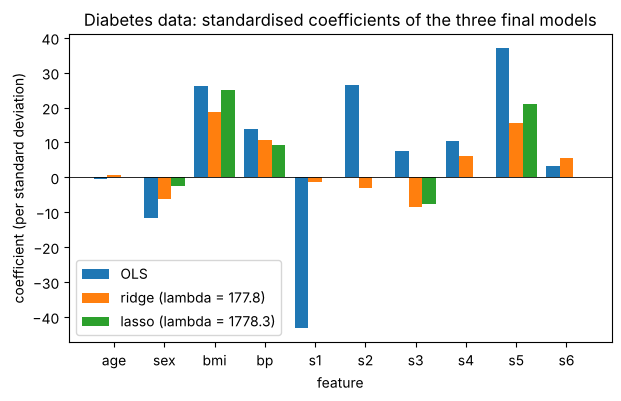


held-out test RMSE with 95% bootstrap CI (2,000 resamples of the 89 test residuals):
  ols    RMSE = 54.16   95% CI [46.88, 61.41]
  ridge  RMSE = 54.61   95% CI [48.65, 60.08]
  lasso  RMSE = 54.62   95% CI [48.10, 60.68]
The intervals overlap almost completely: 89 test patients cannot rank these models.


In [23]:
# ---- diabetes data: 442 patients, 10 baseline features, target = disease progression after one year ----
from sklearn.datasets import load_diabetes
diab = load_diabetes()
X_all, y_all, feature_names = diab.data, diab.target, list(diab.feature_names)
g = np.random.default_rng(0)
perm = g.permutation(len(y_all))
test_idx, train_idx = perm[:89], perm[89:]                    # ~20% held out, touched once at the end
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]
print(f"train {X_train.shape}, test {X_test.shape}; target mean {y_all.mean():.1f}, sd {y_all.std():.1f}")


from sklearn.linear_model import Lasso

def fit_predict(X_tr, y_tr, X_te, method, lam=0.0):
    mu, sd, ym = X_tr.mean(axis=0), X_tr.std(axis=0), y_tr.mean()     # training statistics only
    Z, yc = (X_tr - mu) / sd, y_tr - ym
    if method == "ols":
        beta = np.linalg.lstsq(Z, yc, rcond=None)[0]
    elif method == "ridge":
        beta = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ yc)
    elif method == "lasso":
        beta = Lasso(alpha=lam / len(yc), fit_intercept=False, tol=1e-8, max_iter=50_000).fit(Z, yc).coef_
    return ((X_te - mu) / sd) @ beta + ym, beta

def cv_fold_mse(X, y, method, lam, folds):
    out = []
    for f in range(len(folds)):
        te = folds[f]; tr = np.concatenate([folds[k] for k in range(len(folds)) if k != f])
        pred, _ = fit_predict(X[tr], y[tr], X[te], method, lam)
        out.append(np.mean((y[te] - pred) ** 2))
    return np.array(out)                                               # one MSE per fold

def choose_lam(X, y, method, grid, folds):
    # one-standard-error rule: the largest lambda whose CV MSE is within one SE of the minimum
    fold_mse = np.array([cv_fold_mse(X, y, method, lam, folds) for lam in grid])
    mean, se = fold_mse.mean(axis=1), fold_mse.std(axis=1, ddof=1) / np.sqrt(len(folds))
    i_min = int(np.argmin(mean))
    return float(grid[int(np.max(np.where(mean <= mean[i_min] + se[i_min])[0]))])

grids = {"ridge": np.logspace(-1, 3.5, 19), "lasso": np.logspace(-1, 3.5, 19)}   # wide enough that the choice is interior
outer = np.array_split(g.permutation(len(y_train)), 5)
results = {"ols": [], "ridge": [], "lasso": []}
chosen = {"ridge": [], "lasso": []}
for f in range(5):
    te = outer[f]; tr = np.concatenate([outer[k] for k in range(5) if k != f])
    pred, _ = fit_predict(X_train[tr], y_train[tr], X_train[te], "ols")
    results["ols"].append(np.sqrt(np.mean((y_train[te] - pred) ** 2)))
    inner = np.array_split(g.permutation(len(tr)), 5)                  # inner folds *inside* the outer training set
    for method in ("ridge", "lasso"):
        lam = choose_lam(X_train[tr], y_train[tr], method, grids[method], inner)
        chosen[method].append(lam)
        pred, _ = fit_predict(X_train[tr], y_train[tr], X_train[te], method, lam)
        results[method].append(np.sqrt(np.mean((y_train[te] - pred) ** 2)))
print("nested 5-fold CV RMSE (mean +/- sd over outer folds):")
for method, r in results.items():
    extra = "" if method == "ols" else f"   inner-chosen lambdas: {np.round(chosen[method], 2)}"
    print(f"  {method:6s} {np.mean(r):6.2f} +/- {np.std(r):4.2f}{extra}")

# final models: lambda by 5-fold CV on the whole training set, then refit
folds_final = np.array_split(g.permutation(len(y_train)), 5)
lam_final = {m: choose_lam(X_train, y_train, m, grids[m], folds_final) for m in ("ridge", "lasso")}
print("\nfinal lambdas:", lam_final)
coefs, test_pred = {}, {}
for method in ("ols", "ridge", "lasso"):
    test_pred[method], coefs[method] = fit_predict(X_train, y_train, X_test, method, lam_final.get(method, 0.0))
print("\nstandardised coefficients (feature: OLS / ridge / lasso):")
for j, name in enumerate(feature_names):
    print(f"  {name:4s} {coefs['ols'][j]:8.2f} {coefs['ridge'][j]:8.2f} {coefs['lasso'][j]:8.2f}" + ("   <- dropped by lasso" if coefs["lasso"][j] == 0 else ""))
Zs = (X_train - X_train.mean(0)) / X_train.std(0)
print("correlation(s1, s2) on the training set: %.3f" % np.corrcoef(Zs[:, 4], Zs[:, 5])[0, 1])

w = 0.27
plt.bar(np.arange(10) - w, coefs["ols"], w, label="OLS")
plt.bar(np.arange(10), coefs["ridge"], w, label=f"ridge (lambda = {lam_final['ridge']:.1f})")
plt.bar(np.arange(10) + w, coefs["lasso"], w, label=f"lasso (lambda = {lam_final['lasso']:.1f})")
plt.xticks(range(10), feature_names); plt.axhline(0, color="k", lw=0.6)
plt.title("Diabetes data: standardised coefficients of the three final models")
plt.xlabel("feature"); plt.ylabel("coefficient (per standard deviation)"); plt.legend(); plt.show()

# honest test error with a bootstrap confidence interval
gb = np.random.default_rng(1)
print("\nheld-out test RMSE with 95% bootstrap CI (2,000 resamples of the 89 test residuals):")
for method in ("ols", "ridge", "lasso"):
    resid = y_test - test_pred[method]
    rmse = np.sqrt(np.mean(resid ** 2))
    boot = np.array([np.sqrt(np.mean(gb.choice(resid, size=len(resid), replace=True) ** 2)) for _ in range(2000)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"  {method:6s} RMSE = {rmse:5.2f}   95% CI [{lo:5.2f}, {hi:5.2f}]")
print("The intervals overlap almost completely: 89 test patients cannot rank these models.")

## Score

In [24]:
summary()


Score: 62/62 checks passed  🎉
